In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [9]:
df = pd.read_csv("Dataset .csv")
df.head()

,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


Top 3 Cuisines:
Cuisines
North Indian    3960
Chinese         2735
Fast Food       1986
Name: count, dtype: int64

Percentage:
Cuisines
North Indian    20.091324
Chinese         13.876205
Fast Food       10.076104
Name: proportion, dtype: float64


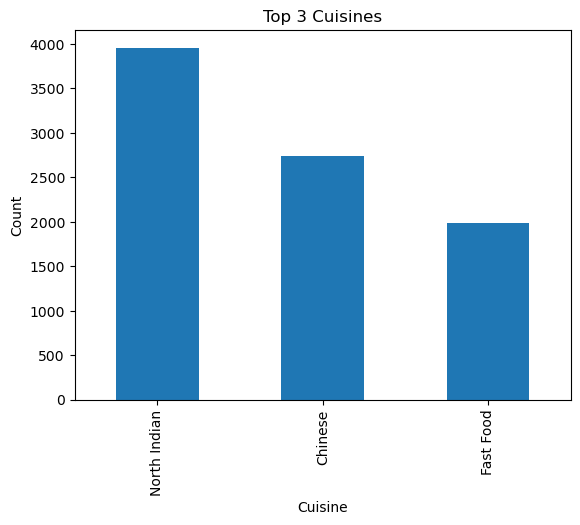

In [11]:
# level 1 
# task 1 
# task - top cuisines
top_cuisines = (
    df['Cuisines']
    .dropna()
    .str.split(', ')
    .explode()
    .value_counts()
    .head(3)
)

print("Top 3 Cuisines:")
print(top_cuisines)

cuisine_percentage = (
    df['Cuisines']
    .dropna()
    .str.split(', ')
    .explode()
    .value_counts(normalize=True)
    .head(3) * 100
)

print("\nPercentage:")
print(cuisine_percentage)

top_cuisines.plot(kind='bar')
plt.title('Top 3 Cuisines')
plt.xlabel('Cuisine')
plt.ylabel('Count')
plt.show()

Top 10 Cities by Number of Restaurants:
City
New Delhi       5473
Gurgaon         1118
Noida           1080
Faridabad        251
Ghaziabad         25
Bhubaneshwar      21
Amritsar          21
Ahmedabad         21
Lucknow           21
Guwahati          21
Name: count, dtype: int64

City with Highest Restaurants:
City: New Delhi
Number of Restaurants: 5473

Top 10 Cities by Average Rating:
City
Inner City          4.900000
Quezon City         4.800000
Makati City         4.650000
Pasig City          4.633333
Mandaluyong City    4.625000
Beechworth          4.600000
London              4.535000
Taguig City         4.525000
Lincoln             4.500000
Tagaytay City       4.500000
Name: Aggregate rating, dtype: float64


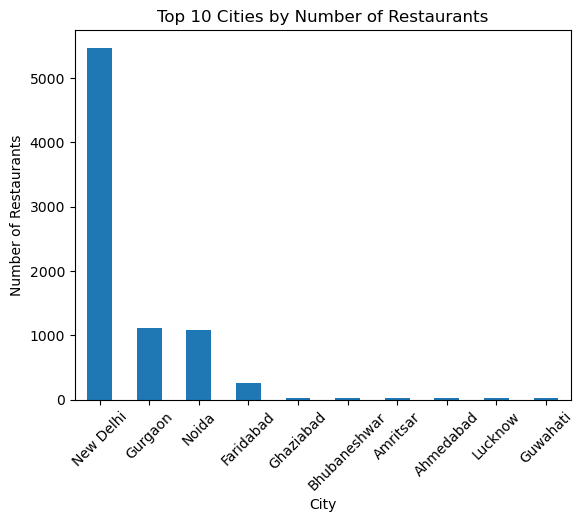

In [12]:
# level 1 
# task  2
# Task  2 - City Analysis

city_count = df['City'].value_counts()

print("Top 10 Cities by Number of Restaurants:")
print(city_count.head(10))


top_city = df['City'].value_counts().idxmax()
top_city_count = df['City'].value_counts().max()

print("\nCity with Highest Restaurants:")
print("City:", top_city)
print("Number of Restaurants:", top_city_count)

city_rating = df.groupby('City')['Aggregate rating'].mean().sort_values(ascending=False)

print("\nTop 10 Cities by Average Rating:")
print(city_rating.head(10))

city_count.head(10).plot(kind='bar')
plt.title('Top 10 Cities by Number of Restaurants')
plt.xlabel('City')
plt.ylabel('Number of Restaurants')
plt.xticks(rotation=45)
plt.show()

Price Range Distribution:
Price range
1    4444
2    3113
3    1408
4     586
Name: count, dtype: int64

Price Range Percentage:
Price range
1    46.529159
2    32.593446
3    14.741912
4     6.135483
Name: proportion, dtype: float64


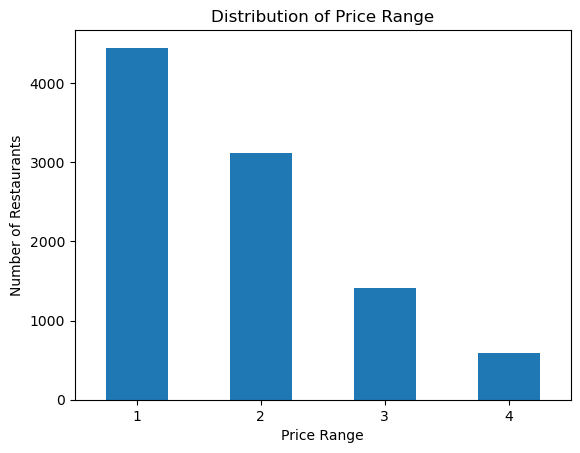

In [13]:
# level 1 
# task  2
# Task  3 - Price Range Distribution

price_count = df['Price range'].value_counts().sort_index()

print("Price Range Distribution:")
print(price_count)

price_percentage = (
    df['Price range']
    .value_counts(normalize=True)
    .sort_index() * 100
)

print("\nPrice Range Percentage:")
print(price_percentage)

price_count.plot(kind='bar')
plt.title('Distribution of Price Range')
plt.xlabel('Price Range')
plt.ylabel('Number of Restaurants')
plt.xticks(rotation=0)
plt.show()

Online Delivery Count:
Has Online delivery
No     7100
Yes    2451
Name: count, dtype: int64

Online Delivery Percentage:
Has Online delivery
No     74.337766
Yes    25.662234
Name: proportion, dtype: float64

Average Rating Comparison:
Has Online delivery
No     2.465296
Yes    3.248837
Name: Aggregate rating, dtype: float64


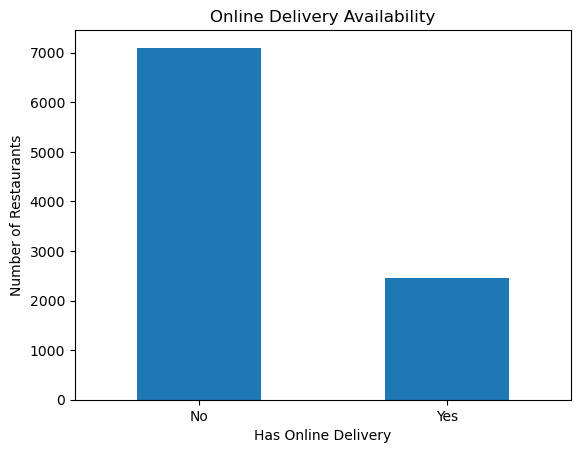

In [14]:
# level 1 
# task  4
# Task  4 - Online Delivery Analysis

online_delivery = df['Has Online delivery'].value_counts()

print("Online Delivery Count:")
print(online_delivery)

online_percentage = (
    df['Has Online delivery']
    .value_counts(normalize=True) * 100
)

print("\nOnline Delivery Percentage:")
print(online_percentage)

rating_comparison = (
    df.groupby('Has Online delivery')['Aggregate rating']
    .mean()
)

print("\nAverage Rating Comparison:")
print(rating_comparison)

online_delivery.plot(kind='bar')
plt.title('Online Delivery Availability')
plt.xlabel('Has Online Delivery')
plt.ylabel('Number of Restaurants')
plt.xticks(rotation=0)
plt.show()